# RNA Seq Pipeline
#### Author: Kylie Gregory 
#### Created On: 11/25/2026
#### Last Modified: 11/27/2026
#### Purpose: Create an RNA-seq pipeline to determine what gene expression changes are consistent across two independent datasets comparing dilated cardiomyopathy (DCM) and healthy (non-failing donor) groups. 

#### Files: 


In [2]:
#load in libraries

#for running rna-seq analysis 
library(DESeq2)

#for manipulating tables 
library(tidyverse)

#for getting sample data from GEO dataset 
library(GEOquery)

#for creating volcano plots
library(EnhancedVolcano)

In [3]:
#read in RNA-seq raw counts dataset


create_raw_counts_table <- function(raw_counts_url, GEO_number){
    #new file name will either be GSE141910.tsv.gz or GSE116250.tsv.gz
    file_name <- paste(GEO_number, ".tsv.gz", sep="")
    download.file(raw_counts_url, file_name)
    count_table <- read.table(file_name, header=T,sep="\t")
    #make GeneID column the unique row identifiers 
    count_table <- column_to_rownames(count_table, var ="GeneID")

    return(count_table)
    
}

In [4]:

#load in column data to map each sample to a condition 

create_column_data <- function(GEO_number){
                               
    #get the GEO series                          
    gse <- getGEO(GEO_number)
                               
    #get the phenotypic data about each sample                           
    sample_data <- pData(gse[[1]])
    
#the condition (DCM vs non-failing) is in different columns for the two datasets we are analysing, so created an if/else block 
                               
#this block filters to DCM and non-failing donor samples, selects only that condition column, changes the name of the column to condition, and edits the exact wording of non-failing and DCM to be consistent among the two datasets to allow downstream code to be modular
                              
                 
    if (GEO_number =="GSE141910")
        {
        col_data <- sample_data %>% filter(characteristics_ch1 %in% c("etiology: Non-Failing Donor",
                                                                    "etiology: Dilated cardiomyopathy (DCM)")) %>% select(characteristics_ch1) %>% rename(condition=characteristics_ch1)
        
        col_data$condition <- sub("etiology: ", "", col_data$condition)
            
    } else{
        col_data <-  col_data <- sample_data %>% filter(`disease:ch1` %in% c("non-failing", "dilated cardiomyopathy")) %>% select(`disease:ch1`) %>% rename(condition=`disease:ch1`)
        
        col_data$condition <- sub("non-failing", "Non-Failing Donor", col_data$condition)
        col_data$condition <- sub("dilated cardiomyopathy", "Dilated cardiomyopathy (DCM)", 
                                  col_data$condition)
    
    }
    
    
    return (col_data)

}



#Link for working with GEOquery: https://bioconductor.org/packages/release/bioc/vignettes/GEOquery/inst/doc/GEOquery.html#why-geoquery
                               



In [5]:
#d1 = dataset 1, d2 = dataset 2
d1_geo_number <- "GSE141910"
d2_geo_number <- "GSE116250"

d1_count_url <- "https://www.ncbi.nlm.nih.gov/geo/download/?type=rnaseq_counts&acc=GSE141910&format=file&file=GSE141910_raw_counts_GRCh38.p13_NCBI.tsv.gz"
d2_count_url <- "https://www.ncbi.nlm.nih.gov/geo/download/?type=rnaseq_counts&acc=GSE116250&format=file&file=GSE116250_raw_counts_GRCh38.p13_NCBI.tsv.gz"

#get each dataset's raw counts matrix
d1_count_table <- create_raw_counts_table(d1_count_url, d1_geo_number)
d2_count_table <- create_raw_counts_table(d2_count_url, d2_geo_number)

#get each dataset's condition information 
d1_col_data <- create_column_data(d1_geo_number)
d2_col_data <- create_column_data(d2_geo_number)
    

Found 1 file(s)



GSE141910_series_matrix.txt.gz



Found 1 file(s)



GSE116250_series_matrix.txt.gz



Using locally cached version of GPL16791 found here:
/tmp/Rtmp7l5MJN/GPL16791.soft.gz 



In [6]:
#count matrix has all of the samples, so need to filter to just get DCM and non-failing donor 

#Once count matrix is filtered, need to re-filter column data to ensure that all samples exist in both tables. When looking at the data on GEO website, there were a few instances that had sample information, but no corresponding raw counts data



create_filtered_tables <- function(col_data, count_table){
    
    #col_data contains only sample numbers belonging to DCM and non failing donors 
    col_data_samples <- rownames(col_data)
    
    #count_table contains sample numbers from every condition 
    all_samples <- colnames(count_table)
    
    #get overlapping sample numbers 
    dcm_nf_samples <- intersect(col_data_samples, all_samples)
    
    #new count table contains only DCM and non-failing donors that we also have informatation about in col_data
    count_table_filtered <- count_table %>% select(all_of(dcm_nf_samples))
    
    #new col_data contains only DCM and non-failing donors that were also available in the filtered count table
    
    col_data_filtered <- col_data %>% filter(rownames(col_data) %in% dcm_nf_samples)
    
    tables <- list(count_table_filtered, col_data_filtered)
    
    return (tables)
    
}





In [8]:
#get column and count data for inputs to DESeq

d1_final_tables <- create_filtered_tables(d1_col_data, d1_count_table)
d2_final_tables <- create_filtered_tables(d2_col_data, d2_count_table)



d1_final_count_table <- d1_final_tables[[1]]
d2_final_count_table <- d2_final_tables[[1]]


d1_final_col_data  <- d1_final_tables[[2]]
d2_final_col_data  <- d2_final_tables[[2]]



#For DESeq2, need rows of col_data to match columns of count_table

#Can run check below to ensure they match
    #rownames(d1_final_col_data) == colnames(d1_final_count_table)
    #rownames(d2_final_col_data) == colnames(d2_final_count_table)


In [9]:
#run DESeq analysis 


run_DESeq <- function(count_table, col_data){
    
    dds <- DESeqDataSetFromMatrix(count_table, col_data, design = ~ condition)
    dds <- DESeq(dds)
    
    return (dds) 
}



In [12]:
d1_dds <- run_DESeq(d1_final_count_table, d1_final_col_data)

d2_dds <- run_DESeq(d2_final_count_table, d2_final_col_data)

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”


  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]



estimating size factors



  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]



estimating dispersions



gene-wise dispersion estimates



... (20 outputs left out)

-- replacing outliers and refitting for 186 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)



estimating dispersions



fitting model and testing



  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]



In [15]:
#Get gene annotations to map GeneIDs to their gene symbols 

create_gene_annot_table <- function(gene_annot_file)
    
    {
    
    #fill = true because rows have unequal length 
    gene_annot_table <- read.table(gene_annot_file, header=TRUE,
                                   sep = "\t", fill=TRUE, quote="")
    
    #only need GeneID and symbol from this table to combine with DESeq table
    gene_annot_table_filtered <- gene_annot_table %>% select(GeneID, Symbol)
    
    #GeneIDs in DESeq table are characters, so convert the GeneID column in this table to character type (originally integer) in order to join the tables by GeneID
    gene_annot_table_filtered$GeneID <- as.character(gene_annot_table_filtered$GeneID)
    
    return (gene_annot_table_filtered)
    
}

In [16]:
gene_annot_file <- "Human.GRCh38.p13.annot.tsv.gz"
gene_annot_table <- create_gene_annot_table(gene_annot_file)


In [26]:
#find differentially expressed genes (p_adjusted < 0.05 and log2fold change >=1.5)


get_DESeq_results <- function(dds, gene_annot_table ){
    

    res <- results(dds,contrast=c("condition","Dilated cardiomyopathy (DCM)", "Non-Failing Donor"), alpha = 0.05, lfcThreshold = 1.5)

    #make GeneID a column name in order to join with gene_annot_table by GeneID
    res <- as.data.frame(res) %>% rownames_to_column(var="GeneID")

    #need to get all genes for fisher test to see which genes were tested in both datasets for significance
    all_genes <- res
    
    significant_genes <- res %>% filter(!is.na(res$padj) & padj < 0.05)
    upreg_genes <- significant_genes %>% filter(log2FoldChange > 0) 
    downreg_genes <- significant_genes %>% filter(log2FoldChange < 0) 
    
    
    #merge with gene_annot_table to get corresponding gene symbols
    
    all_genes_with_symbol <- left_join(all_genes, gene_annot_table, by = "GeneID")


    
    up_genes_with_symbol <- left_join(upreg_genes, gene_annot_table, by = "GeneID")
    #make Symbol the unique row identifiers
    up_genes_with_symbol <- column_to_rownames(up_genes_with_symbol, var="Symbol")
    
 
    down_genes_with_symbol <- left_join(downreg_genes, gene_annot_table, by = "GeneID")
    #make Symbol the unique row identifiers
    down_genes_with_symbol <- column_to_rownames(down_genes_with_symbol, var="Symbol")
    

    
    genes <- list(up_genes_with_symbol, down_genes_with_symbol, all_genes_with_symbol)
    
    }
    


In [27]:
#get all genes test, upregulated genes, and downregulated genes from both datasets

d1_genes_of_interest <- get_DESeq_results(d1_dds, gene_annot_table)
d1_up_genes_table <- d1_genes_of_interest[[1]]
d1_down_genes_table <- d1_genes_of_interest[[2]]
d1_all_genes_table <- d1_genes_of_interest[[3]]


d2_genes_of_interest <- get_DESeq_results(d2_dds, gene_annot_table)
d2_up_genes_table <- d2_genes_of_interest[[1]]
d2_down_genes_table <- d2_genes_of_interest[[2]]
d2_all_genes_table <- d2_genes_of_interest[[3]]

In [28]:
head(d1_up_genes_table)

,GeneID,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LINC02593,100130417,18.497064,2.194921,0.1435808,15.287006,6.494273e-07,1.305909e-04
NPPA-AS1,100379251,9707.713541,2.675511,0.1842482,14.521231,8.852145e-11,3.054646e-08
NPPA,4878,32038.758405,2.771917,0.1952611,14.195951,3.660513e-11,1.382635e-08
FHAD1,114827,8.345444,2.060591,0.1059247,19.453357,6.037653e-08,1.383266e-05
FHAD1-AS1,101927417,26.279741,3.163171,0.1157135,27.336233,3.812302e-47,2.663941e-43
PLA2G2D,26279,2.221539,3.101638,0.3172414,9.776902,2.224808e-07,4.711031e-05


In [31]:
#get gene names for Fisher test 

d1_up_gene_names <- rownames(d1_up_genes_table)
d2_up_gene_names <- rownames(d2_up_genes_table)
d1_all_gene_names <- d1_all_genes_table$Symbol

d1_down_gene_names <- rownames(d1_down_genes_table)
d2_down_gene_names <- rownames(d2_down_genes_table)
d2_all_gene_names <- d2_all_genes_table$Symbol

In [32]:
#Fisher test for upregulated genes


#determine genes tested for significance in both datasets
all_genes_overlap_fisher <- intersect(d1_all_gene_names, d2_all_gene_names)

#determine upregulated genes in dataset 1 that were tested for significance in both datasets
d1_up_genes_fisher <- intersect(all_genes_overlap_fisher, d1_up_gene_names)

#determine upregulated genes in dataset 2 that were tested for significance in both datasets
d2_up_genes_fisher <- intersect(all_genes_overlap_fisher, d2_up_gene_names)

#determine # of genes tested for significance in both datasets that were not significantly upregulated in either dataset 
a_up <- length(all_genes_overlap_fisher) - length(union(d1_up_genes_fisher, d2_up_genes_fisher))

#determine # of genes significantly upregulated in dataset 1, but not significantly upregulated in dataset 2 that were tested for significance in both datasets
b_up <- length(setdiff(d1_up_genes_fisher, d2_up_genes_fisher))

#determine # of genes significantly upregulated in dataset 2, but not significantly upregulated in dataset 1 that were tested for significance in both datasets
c_up <- length(setdiff(d2_up_genes_fisher, d1_up_genes_fisher))

#determine # of genes that were significanty upregulated in both datasets
d_up <- length(intersect(d1_up_genes_fisher, d2_up_genes_fisher))


fisher_up_reg_results <- fisher.test(matrix(c(a_up, b_up, c_up, d_up), nrow=2), alternative="greater")

fisher_up_reg_results



#running fisher's exact test 
#documentation for test: https://bioconductor.org/packages/devel/bioc/manuals/GeneOverlap/man/GeneOverlap.pdf
# matrix(c(n - union(A,B), setdiff(A,B), setdiff(B,A), intersect(A,B)), nrow=2)
# n = number of genes, A = number of genes in set A, B = number of genes in set B


	Fisher's Exact Test for Count Data

data:  matrix(c(a_up, b_up, c_up, d_up), nrow = 2)
p-value < 2.2e-16
alternative hypothesis: true odds ratio is greater than 1
95 percent confidence interval:
 141.998     Inf
sample estimates:
odds ratio 
  278.8351 


In [33]:
#Fisher test for downregulated genes

#determine genes tested for significance in both datasets
all_genes_overlap_fisher <- intersect(d1_all_gene_names, d2_all_gene_names)

#determine downregulated genes in dataset 1 that were tested for significance in both datasets
d1_down_genes_fisher <- intersect(all_genes_overlap_fisher, d1_down_gene_names)

#determine downregulated genes in dataset 2 that were tested for significance in both datasets
d2_down_genes_fisher <- intersect(all_genes_overlap_fisher, d2_down_gene_names)

#determine # of genes tested for significance in both datasets that were not significantly downregulated in either dataset 
a_down <- length(all_genes_overlap_fisher) - length(union(d1_down_genes_fisher, d2_down_genes_fisher))

#determine # of genes significantly downregulated in dataset 1, but not significantly downregulated in dataset 2 that were tested for significance in both datasets
b_down <- length(setdiff(d1_down_genes_fisher, d2_down_genes_fisher))

#determine # of genes significantly downregulated in dataset 2, but not significantly downregulated in dataset 1 that were tested for significance in both datasets
c_down <- length(setdiff(d2_down_genes_fisher, d1_down_genes_fisher))

#determine # of genes that were significanty downregulated in both datasets
d_down <- length(intersect(d1_down_genes_fisher, d2_down_genes_fisher))

fisher_down_reg_results <- fisher.test(matrix(c(a_down, b_down, c_down, d_down), nrow=2), alternative="greater")

fisher_down_reg_results


	Fisher's Exact Test for Count Data

data:  matrix(c(a_down, b_down, c_down, d_down), nrow = 2)
p-value < 2.2e-16
alternative hypothesis: true odds ratio is greater than 1
95 percent confidence interval:
 455.9341      Inf
sample estimates:
odds ratio 
  2001.432 


In [34]:
head(d1_all_genes_table)

,GeneID,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,Symbol
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,100287102,5.0566072,0.08094584,0.13909746,0.5819361,1.0000000,1,DDX11L1
2,653635,516.3704668,0.38778617,0.09673773,4.0086342,1.0000000,1,WASH7P
3,102466751,14.6300564,0.09313151,0.08630538,1.0790927,1.0000000,1,MIR6859-1
4,107985730,0.6495627,0.66436795,0.21446341,3.0978149,0.9999512,1,MIR1302-2HG
5,100302278,0.1551513,0.11387351,0.45421839,0.2507021,0.9990525,NA,MIR1302-2
6,645520,1.4687312,0.83640533,0.17034634,4.9100282,0.9999510,1,FAM138A


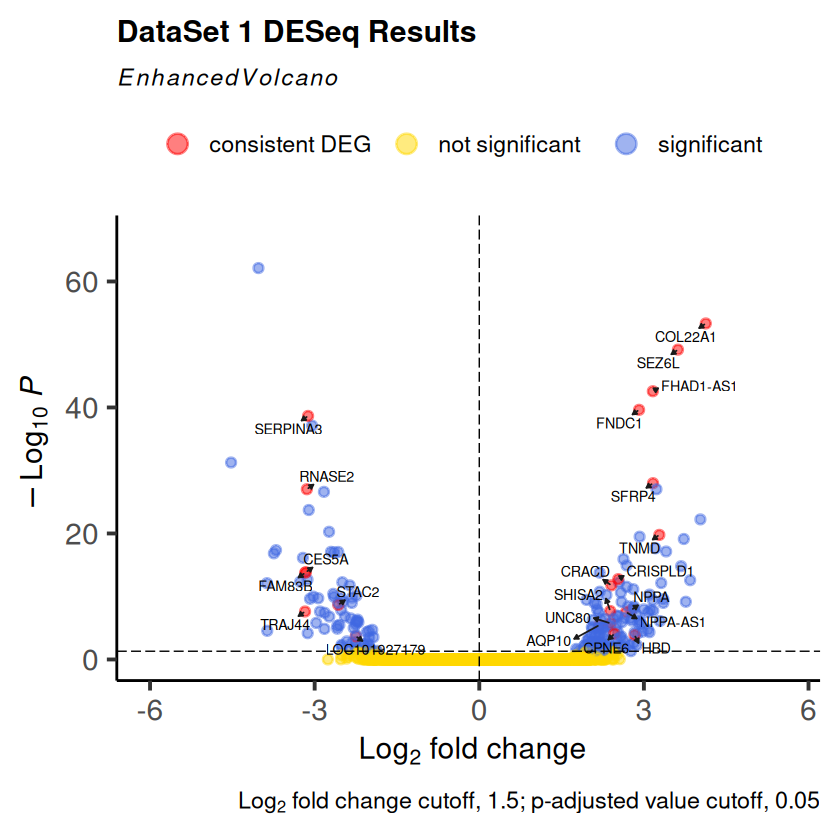

In [40]:
#Create Volcano Plot for Dataset 1, labeling the consistently expressed genes across both datasets. 
# 3 different colors: gold = not significant, blue = significant, but not consistent across both datastes (downregulated or upregulated), red = significant across both datasets (downregulated or upregulated)


#Fisher's test was significant (p-value was 2.2e-16, so get consistently significant genes) 

consistent_up_genes <- intersect(d1_up_genes_fisher, d2_up_genes_fisher)
consistent_down_genes <- intersect(d1_down_genes_fisher, d2_down_genes_fisher)
consistently_sig_genes <- union(consistent_up_genes, consistent_down_genes)


#get non-consistently significant_genes in dataset1
all_significant_genes <- union(d1_up_genes_fisher, d1_down_genes_fisher)
non_consistent_sig_genes <- setdiff(all_significant_genes, consistently_sig_genes)



res_1 <- results(d1_dds,contrast=c("condition","Dilated cardiomyopathy (DCM)", "Non-Failing Donor"))


res_1 <- as.data.frame(res_1) %>% rownames_to_column(var="GeneID")

res_1 <- left_join(res_1, gene_annot_table, by = "GeneID")



keyvals <- ifelse(d1_all_genes_table$Symbol %in% non_consistent_sig_genes, "royalblue", ifelse(d1_all_genes_table$Symbol %in% consistently_sig_genes, "red", "gold"))

names(keyvals)[keyvals == 'red'] <- 'consistent DEG'
names(keyvals)[keyvals == 'gold'] <- 'not significant'
names(keyvals)[keyvals == 'royalblue'] <- 'significant'


EnhancedVolcano(d1_all_genes_table, x="log2FoldChange", y="padj", lab = d1_all_genes_table$Symbol, selectLab = consistently_sig_genes, title="DataSet 1 DESeq Results", pCutoff = 0.05, FCcutoff = 0, labSize = 3, caption = bquote(~Log[2]~ "fold change cutoff, 1.5; p-adjusted value cutoff, 0.05"), drawConnectors = TRUE, colCustom = keyvals, colAlpha=0.5, gridlines.major=FALSE, gridlines.minor=FALSE)



#not sure if should do plot with res_1 (the original result) or the result that is after hypothesis test with p_adj < 0.05 which is table d1_all_genes_table

In [ ]:
#create volcano plot and label consistent sig genes only 

res_1 <- results(d1_dds,contrast=c("condition","Dilated cardiomyopathy (DCM)", "Non-Failing Donor"))




ggplot(res_1, aes(x=log2FoldChange,y= -log10(padj))) + geom_point(data=d1_up_genes, fill="steelblue", colour="black") + geom_point(data=d1_down_genes, fill="firebrick", colour="black") + labs(title = "Volcano Plot", x = "Log2 Fold Change", y = "-Log10 Adjusted P-Value")


In [ ]:
res_1 <- results(d1_dds,contrast=c("condition","Dilated cardiomyopathy (DCM)", "Non-Failing Donor"))


res_1 <- as.data.frame(res_1) %>% rownames_to_column(var="GeneID")

res_1 <- left_join(res_1, gene_annot_table, by = "GeneID")

sig_genes_plot <- union(d1_up_genes_fisher, d1_down_genes_fisher)

sig_genes_not_cons <- setdiff(sig_genes_plot, sig)


keyvals <- ifelse(res_1$Symbol %in% sig_genes_not_cons, "royalblue", ifelse(res_1$Symbol %in% sig, "red", "gold"))

names(keyvals)[keyvals == 'red'] <- 'consistent DEG'
names(keyvals)[keyvals == 'gold'] <- 'not significant'
names(keyvals)[keyvals == 'royalblue'] <- 'significant'


EnhancedVolcano(res_1, x="log2FoldChange", y="padj", lab = res_1$Symbol, selectLab = sig, title="DataSet 1 DESeq Results", pCutoff = 0.05, FCcutoff = 1.5, labSize = 3, caption = bquote(~Log[2]~ "fold change cutoff, 1.5; p-adjusted value cutoff, 0.05"), drawConnectors = TRUE, colCustom = keyvals, colAlpha=0.5, cutoffLineType='blank', gridlines.major=FALSE, gridlines.minor=FALSE)


In [ ]:
res_2 <- results(d2_dds,contrast=c("condition","Dilated cardiomyopathy (DCM)", "Non-Failing Donor"))


res_2 <- as.data.frame(res_2) %>% rownames_to_column(var="GeneID")

res_2 <- left_join(res_2, gene_annot_table, by = "GeneID")

sig_genes_plot <- union(d2_up_genes_fisher, d2_down_genes_fisher)

sig_genes_not_cons <- setdiff(sig_genes_plot, sig)


keyvals <- ifelse(res_2$Symbol %in% sig_genes_not_cons, "royalblue", ifelse(res_2$Symbol %in% sig, "red", "gold"))

names(keyvals)[keyvals == 'red'] <- 'consistent DEG'
names(keyvals)[keyvals == 'gold'] <- 'not significant'
names(keyvals)[keyvals == 'royalblue'] <- 'significant'


EnhancedVolcano(res_2, x="log2FoldChange", y="padj", lab = res_2$Symbol, selectLab = sig, title="DataSet 2 DESeq Results", pCutoff = 0.05, FCcutoff = 1.5, labSize = 3, caption = bquote(~Log[2]~ "fold change cutoff, 1.5; p-adjusted value cutoff, 0.05"), drawConnectors = TRUE, colCustom = keyvals, colAlpha=0.5, cutoffLineType='blank', gridlines.major=FALSE, gridlines.minor=FALSE)




In [ ]:
#record the functions and versions used for analysis

sessionInfo()